# Simon's living coding session nr. 2

18-11-2026

topic: bridge and stopping conditions

Chris's version. simon was typing fast so something is not updated yet, so there's something here that's not working

In [39]:
import numpy as np
from amuse.lab import *
import matplotlib.pyplot as plt
from amuse.plot import scatter

from amuse.ext.orbital_elements import get_orbital_elements_from_binary
from amuse.couple import bridge

# from amuse.ext.orbital_elements import new_binary_from_orbital_elements
# from amuse.ext.orbital_elements import get_orbital_elements_from_binary
# from amuse.community.ph4.interface import Ph4
# from matplotlib import pyplot as plt
# from amuse.plot import scatter
# from amuse.ext.orbital_elements import semimajor_axis_to_orbital_period
# from amuse.units import units, nbody_system

In [2]:
def init_cluster(N, Rvir):
    masses = new_salpeter_mass_distribution(N, 0.1 | units.Msun, 100 | units.Msun)
    converter = nbody_system.nbody_to_si(masses.sum(), Rvir)
    bodies = new_plummer_model(N, convert_nbody=converter)
    bodies.mass = masses
    bodies.scale_to_standard(converter)  # to put in virial equilibrium. 
    # bc we used plummer model we broke it. ie low m star moving too slpw and high
    # mass mv too fast
    bodies.radius = 1000 | units.au
    return bodies

In [3]:
def plot_cluster(bodies):
    scatter(bodies.x, bodies.y)
    # plt.show()

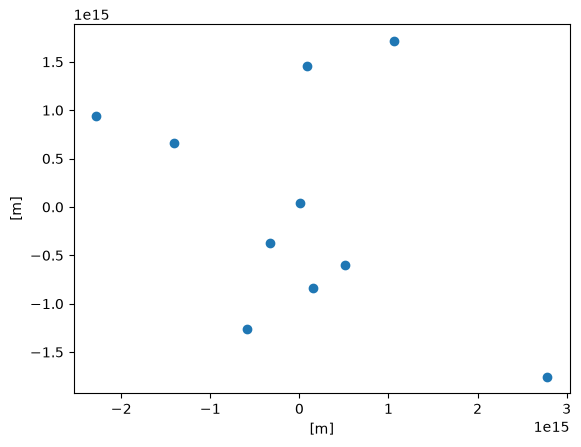

In [4]:
np.random.seed(1234)
bodies = init_cluster(10, 0.1 | units.pc)
plot_cluster(bodies)

bodies_init = bodies.copy()

In [37]:
def get_enc_particles(stop_cond, bodies):
    particles_in_encounter = Particles(0)
    for ci in range(len(stopping_cond.particles(0))):
        particles_in_encounter = Particles(
            particles=[
                stopping_cond.particles(0)[ci],
                stopping_cond.particles(1)[ci],

            ]
        )

        local_particle_in_encounter = particles_in_encounter.get_intersecting_subset_in(bodies)
        local_particle_in_encounter.radius = 0 | units.au


        orbit = get_orbital_elements_from_binary(particles_in_encounter)
        print('orbit:')
        print(orbit)

        # encountering_particles = stopping_cond.particles()

        print(particles_in_encounter)
        # for ep in encountering_particles:
        #     print('col between')
        #     print(ep)


    return particles_in_encounter

In [44]:
def plot_cluster(bodies, gas):
    plt.scatter(
        gas.x.value_in(units.pc), gas.y.value_in(units.pc),
        s=100, c='r', alpha=0.05
    )
    plt.scatter(bodies.x.value_in(units.pc), bodies.y.value_in(units.pc))
    plt.show()

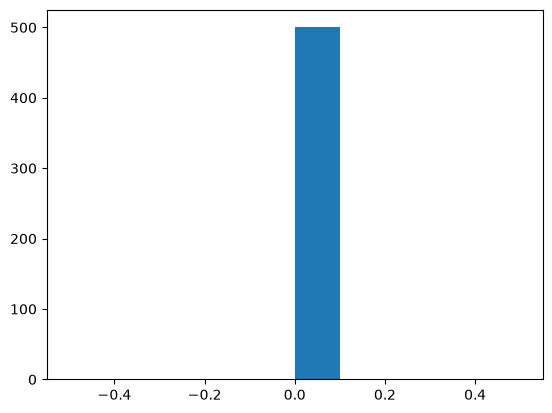

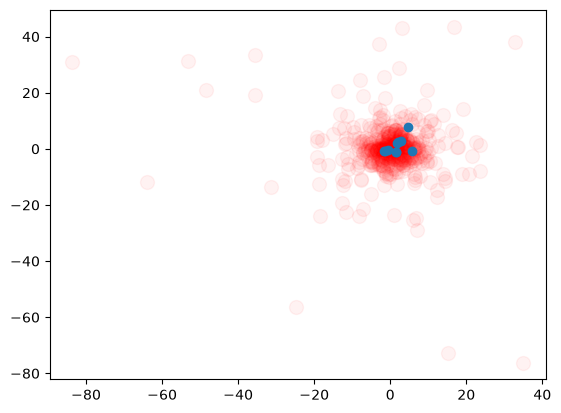

time is 0.10 Myr
time is 0.20 Myr
time is 0.30 Myr
time is 0.40 Myr
time is 0.50 Myr
time is 0.60 Myr
time is 0.70 Myr
time is 0.80 Myr
time is 0.90 Myr
time is 1.00 Myr


/tmp/ipykernel_3042103/2450397479.py:72: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


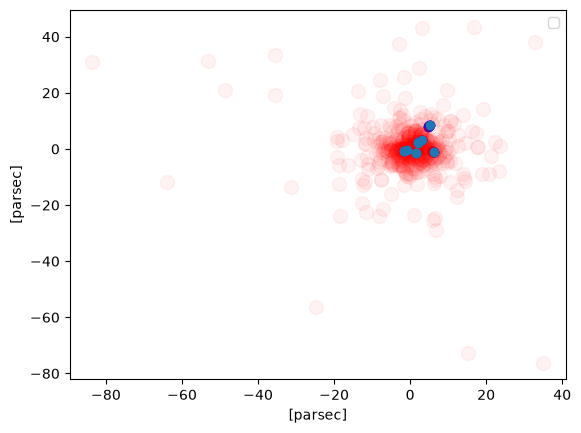

In [53]:
converter = nbody_system.nbody_to_si(
    bodies.mass.sum(),
    np.mean(bodies.position.lengths())
)
gravity = ph4(convert_nbody=converter)
gravity.particles.add_particles(bodies)

channels = {}
channels['to_gra'] = bodies.new_channel_to(gravity.particles)
channels['from_gra'] = gravity.particles.new_channel_to(bodies)

stopping_cond = gravity.stopping_conditions.collision_detection
stopping_cond.enable()

converter_gas = nbody_system.nbody_to_si(
    0.01 * bodies.mass.sum(), 2 * np.mean(bodies.position.lengths())
)
Ngas = 500
gas = new_plummer_gas_model(Ngas, converter_gas)

v = gas.velocity.lengths()
plt.hist(v.value_in(units.kms))
plt.show()

plot_cluster(bodies, gas)

hydro = Fi(converter_gas)
hydro.particles.add_particles(gas)

channels['to_hy'] = gas.new_channel_to(hydro.particles)
channels['from_hy'] = hydro.particles.new_channel_to(gas)

grahydro = bridge.Bridge()
grahydro.add_system(gravity, (hydro, ))
grahydro.add_system(hydro, (gravity, ))
dt = 0.1 | units.Myr
grahydro.timestep = 0.01 * dt

time = 0 | units.yr
time_end = 1 | units.Myr

while time<time_end:
    time += dt
    grahydro.evolve_model(time)
    channels['from_gra'].copy()
    channels['from_hy'].copy()

    print(f'time is {time.value_in(units.Myr):.2f} Myr')
    colliding_pair = get_enc_particles(stopping_cond, bodies)

    channels['to_gra'].copy()
    scatter(bodies.x.in_(units.pc), bodies.y.in_(units.pc), c='b')

    if len(colliding_pair) > 1:
        scatter(colliding_pair.x.in_(units.pc), colliding_pair.y.in_(units.pc), c='orange')

    grahydro.evolve_model(time)

    channels['from_gra'].copy()
    channels['from_hy'].copy()

    # break

# scatter(bodies_init.x, bodies_init.y, c='r', label='init')
# scatter(bodies.x, bodies.y)
plt.scatter(
    gas.x.value_in(units.pc), gas.y.value_in(units.pc),
    s=100, alpha=0.05, c='r'
)
plt.scatter(bodies.x.value_in(units.pc), bodies.y.value_in(units.pc))

plt.legend()
plt.show()

gravity.stop()
hydro.stop()